# Clasificacion de Sonidos Cotidianos mediante un Modelo TinyML Ultracompacto

**Proyecto Academico de TinyML**

Este notebook presenta el flujo completo de ingenieria para clasificar 4 sonidos cotidianos del dataset ESC-50 (`clapping`, `clock_alarm`, `door_wood_knock`, `keyboard_typing`), utilizando una Red Neuronal Convolucional (CNN) ultracompacta disenada para microcontroladores y dispositivos de borde, aplicando cuantizacion INT8 con TensorFlow Lite.

## 1. Verificacion del Dataset y Comprobacion de Archivos
Comprobamos la presencia de los 160 archivos WAV (40 archivos por clase), verificando frecuencia de muestreo (44.1 kHz), canales mono y duracion (5.0 s).

In [15]:
import os
import sys
import warnings
import logging
import importlib

# Configurar ejecucion en CPU y silenciar avisos de GPU/oneDNN
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
warnings.filterwarnings('ignore')
logging.getLogger('tensorflow').setLevel(logging.ERROR)

# Asegurar que el directorio de trabajo apunte a la raiz del proyecto
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

# Incluir carpeta src en el path de Python
src_dir = os.path.abspath('src')
if src_dir not in sys.path:
    sys.path.append(src_dir)

# Importar y recargar verify_dataset para evitar modulos cacheados
import verify_dataset
importlib.reload(verify_dataset)
verify_dataset.verify_dataset()

FASE 1: VERIFICACION DEL DATASET
Directorio base: c:\Users\Usuario\Desktop\lucianaIA2\dataset\ESC-50-TinyML
Clases detectadas: ['clapping', 'clock_alarm', 'door_wood_knock', 'keyboard_typing']

Clase: clapping
  Archivos encontrados : 40 (esperado: 40)
  Frecuencia muestreo  : {44100} Hz
  Canales              : {1}
  Duracion promedio    : 5.00 s

Clase: clock_alarm
  Archivos encontrados : 40 (esperado: 40)
  Frecuencia muestreo  : {44100} Hz
  Canales              : {1}
  Duracion promedio    : 5.00 s

Clase: door_wood_knock
  Archivos encontrados : 40 (esperado: 40)
  Frecuencia muestreo  : {44100} Hz
  Canales              : {1}
  Duracion promedio    : 5.00 s

Clase: keyboard_typing
  Archivos encontrados : 40 (esperado: 40)
  Frecuencia muestreo  : {44100} Hz
  Canales              : {1}
  Duracion promedio    : 5.00 s

------------------------------------------------------------
Total de archivos encontrados : 160
Total de archivos esperados   : 160
Verificacion completada con 

{'clapping': 40,
 'clock_alarm': 40,
 'door_wood_knock': 40,
 'keyboard_typing': 40}

## 2. Exploracion de Datos y Visualizacion de Ondas Sonoras
Generamos la grafica de distribucion uniforme de clases y comparamos la firma temporal de las formas de onda.

Grafica guardada: c:\Users\Usuario\Desktop\lucianaIA2\results\class_distribution.png
Grafica guardada: c:\Users\Usuario\Desktop\lucianaIA2\results\waveform_sample.png
Grafica guardada: c:\Users\Usuario\Desktop\lucianaIA2\results\waveform_comparison.png


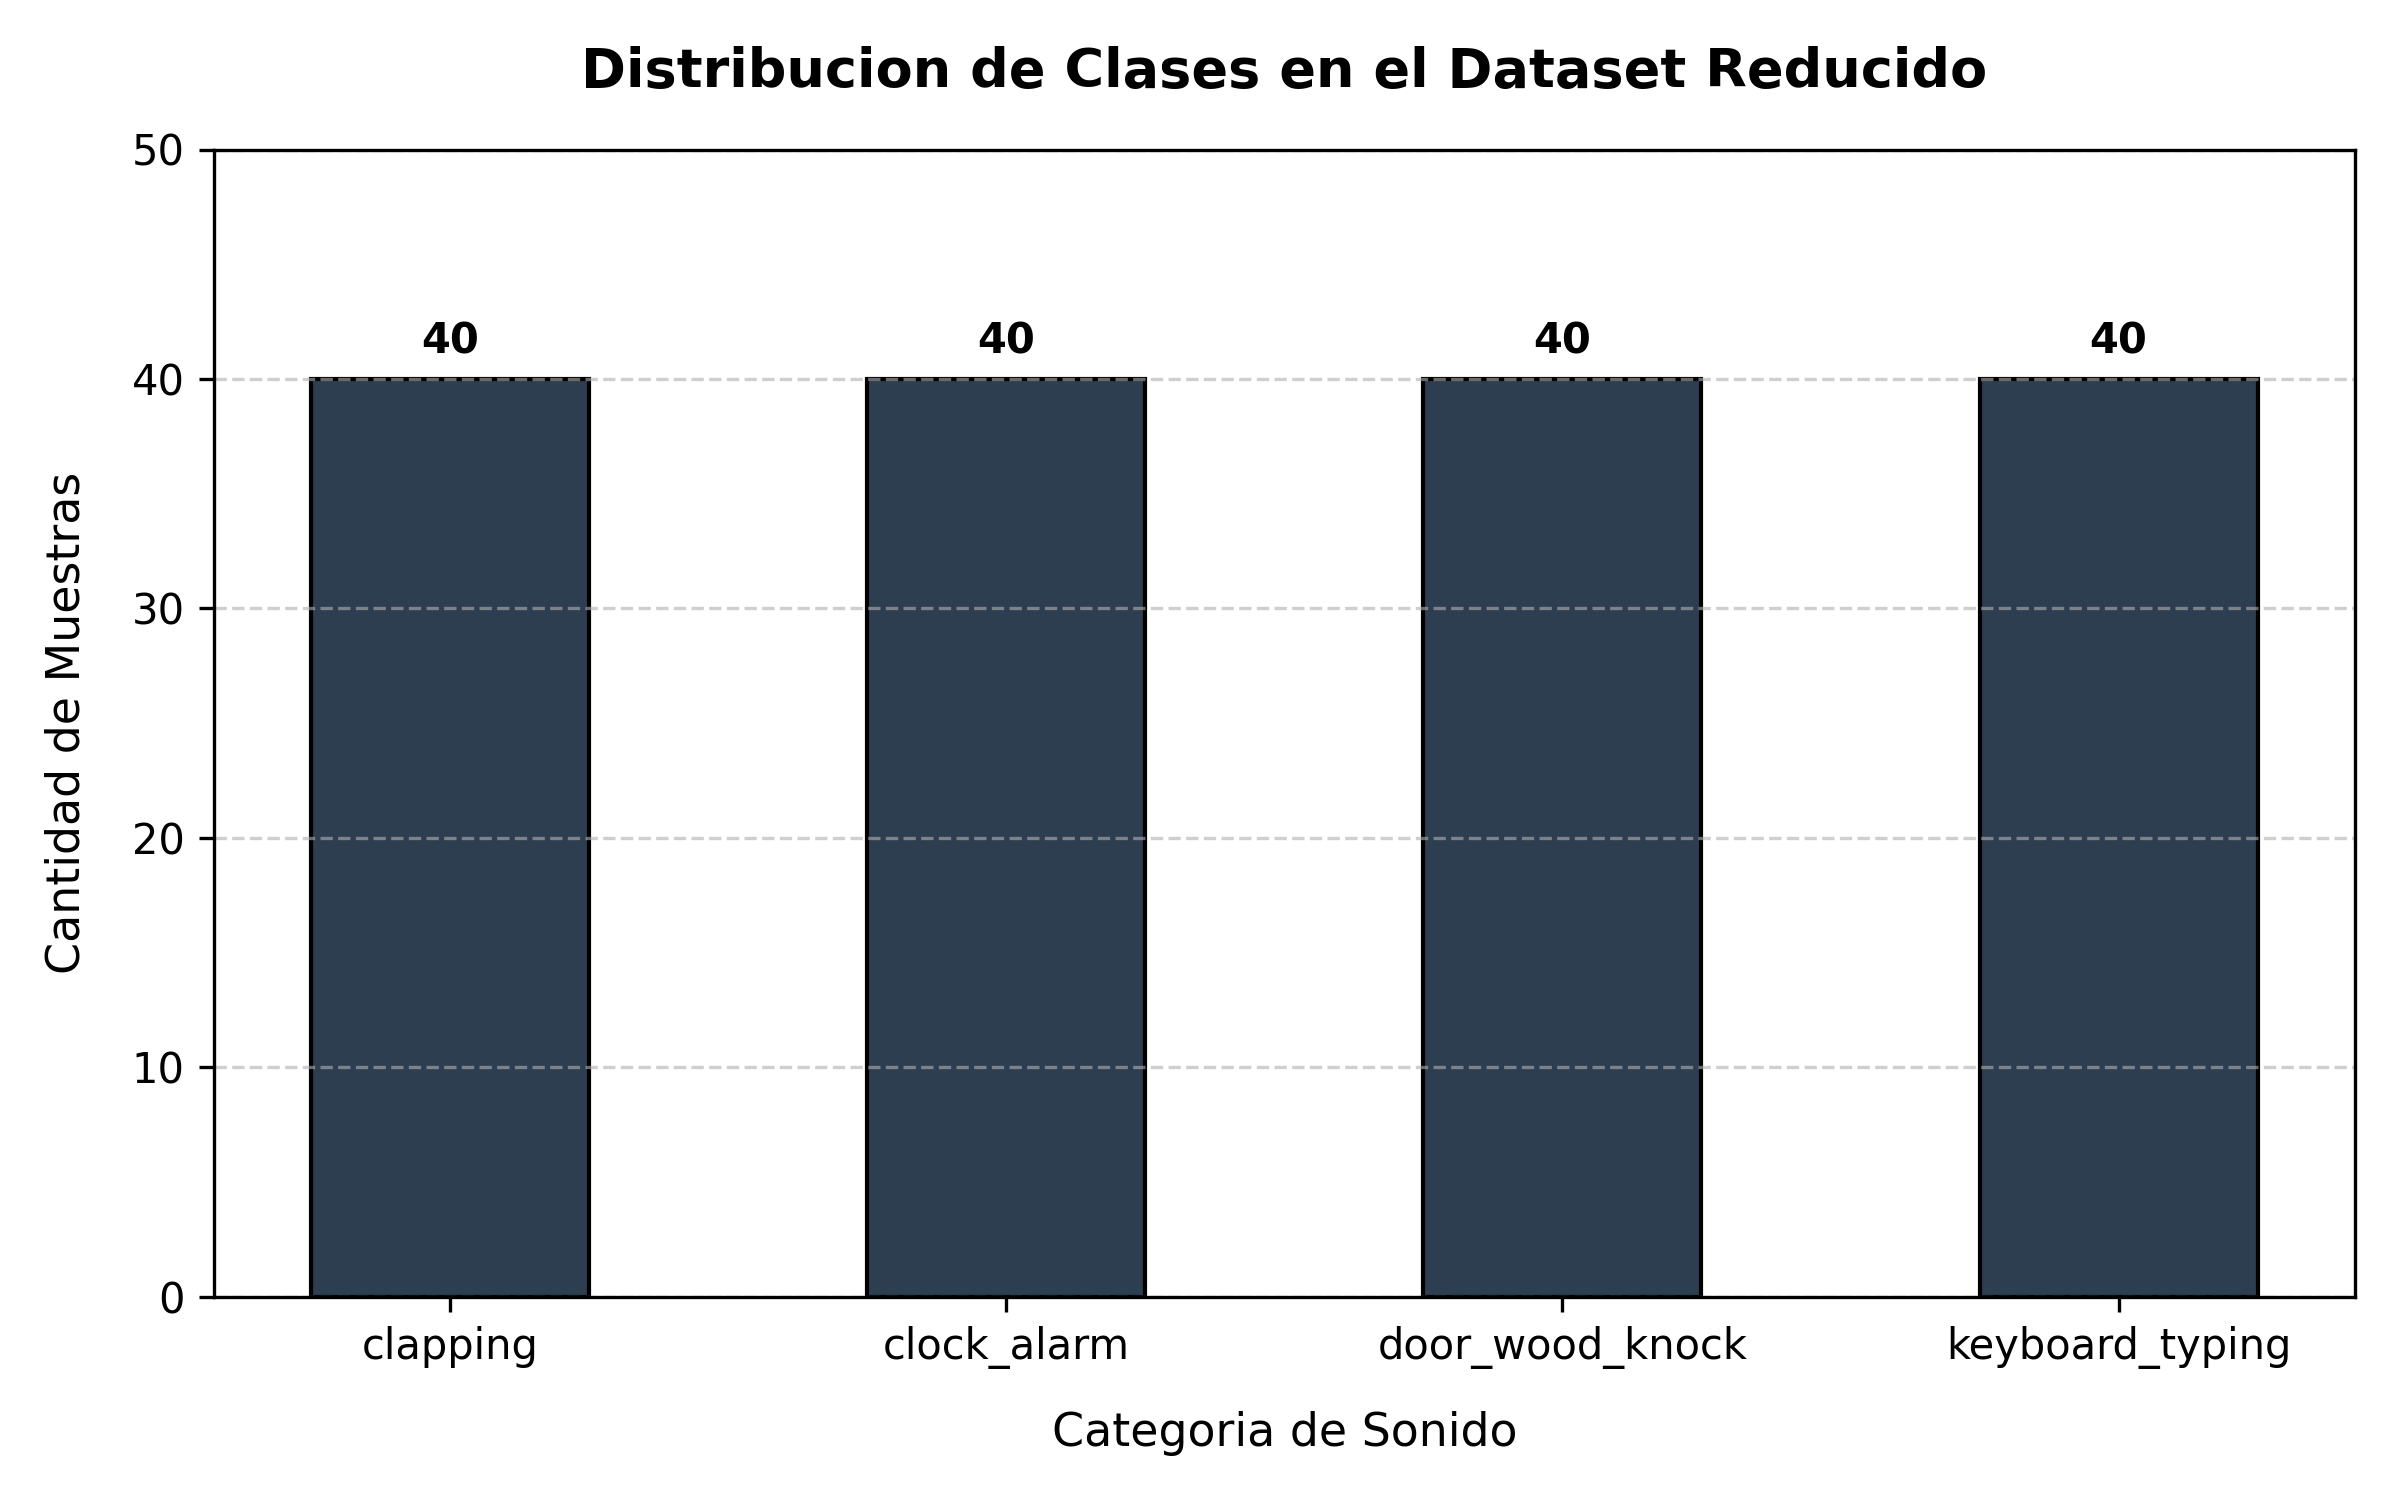

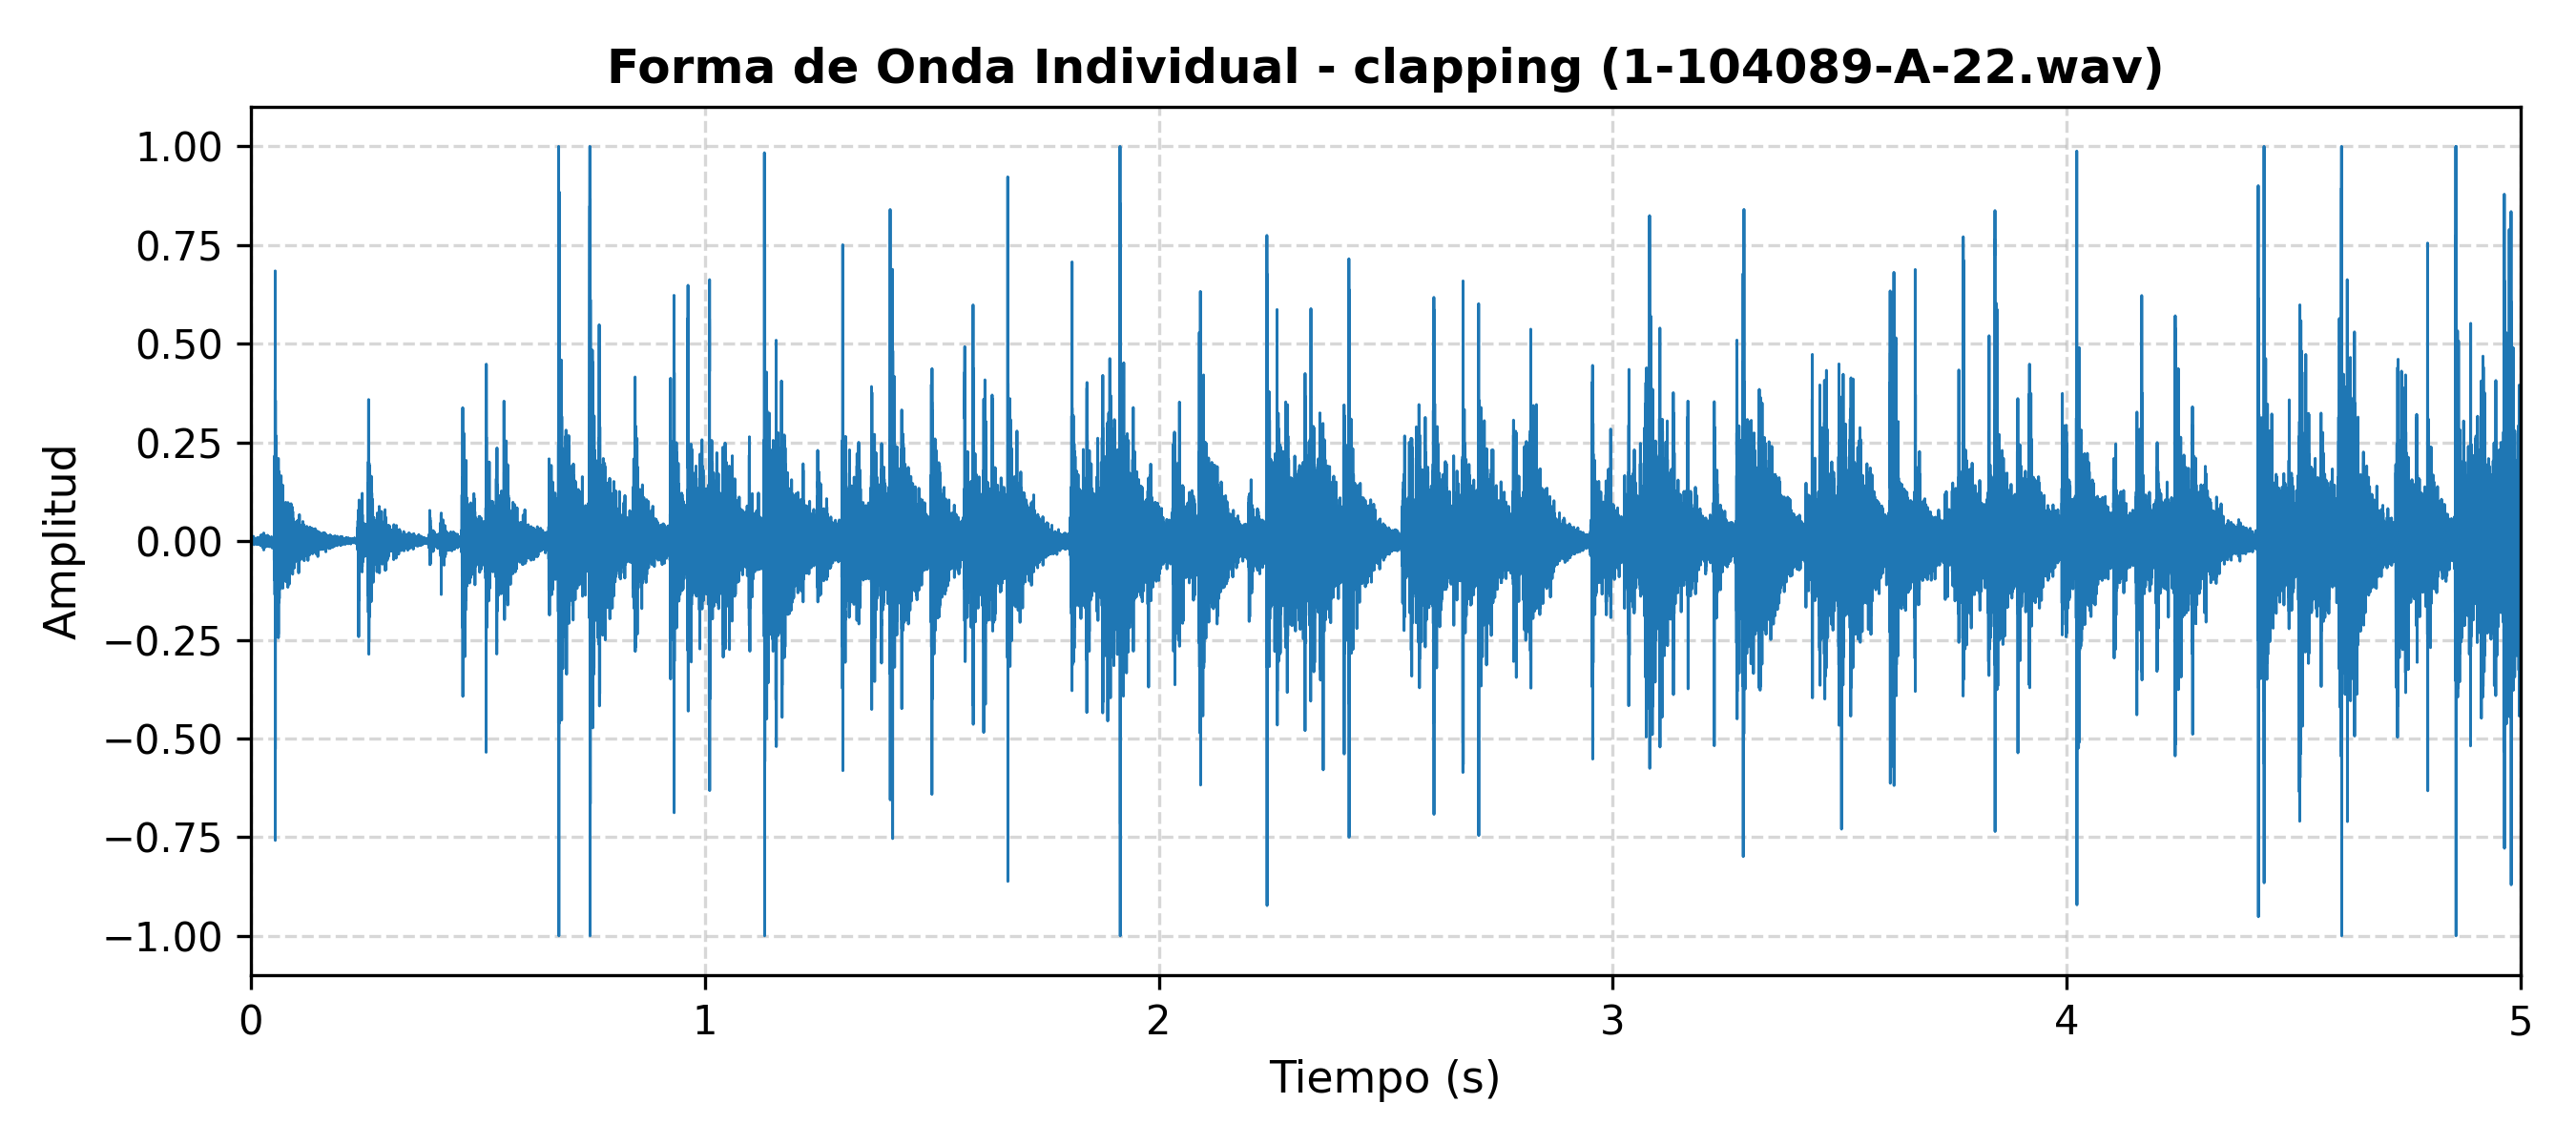

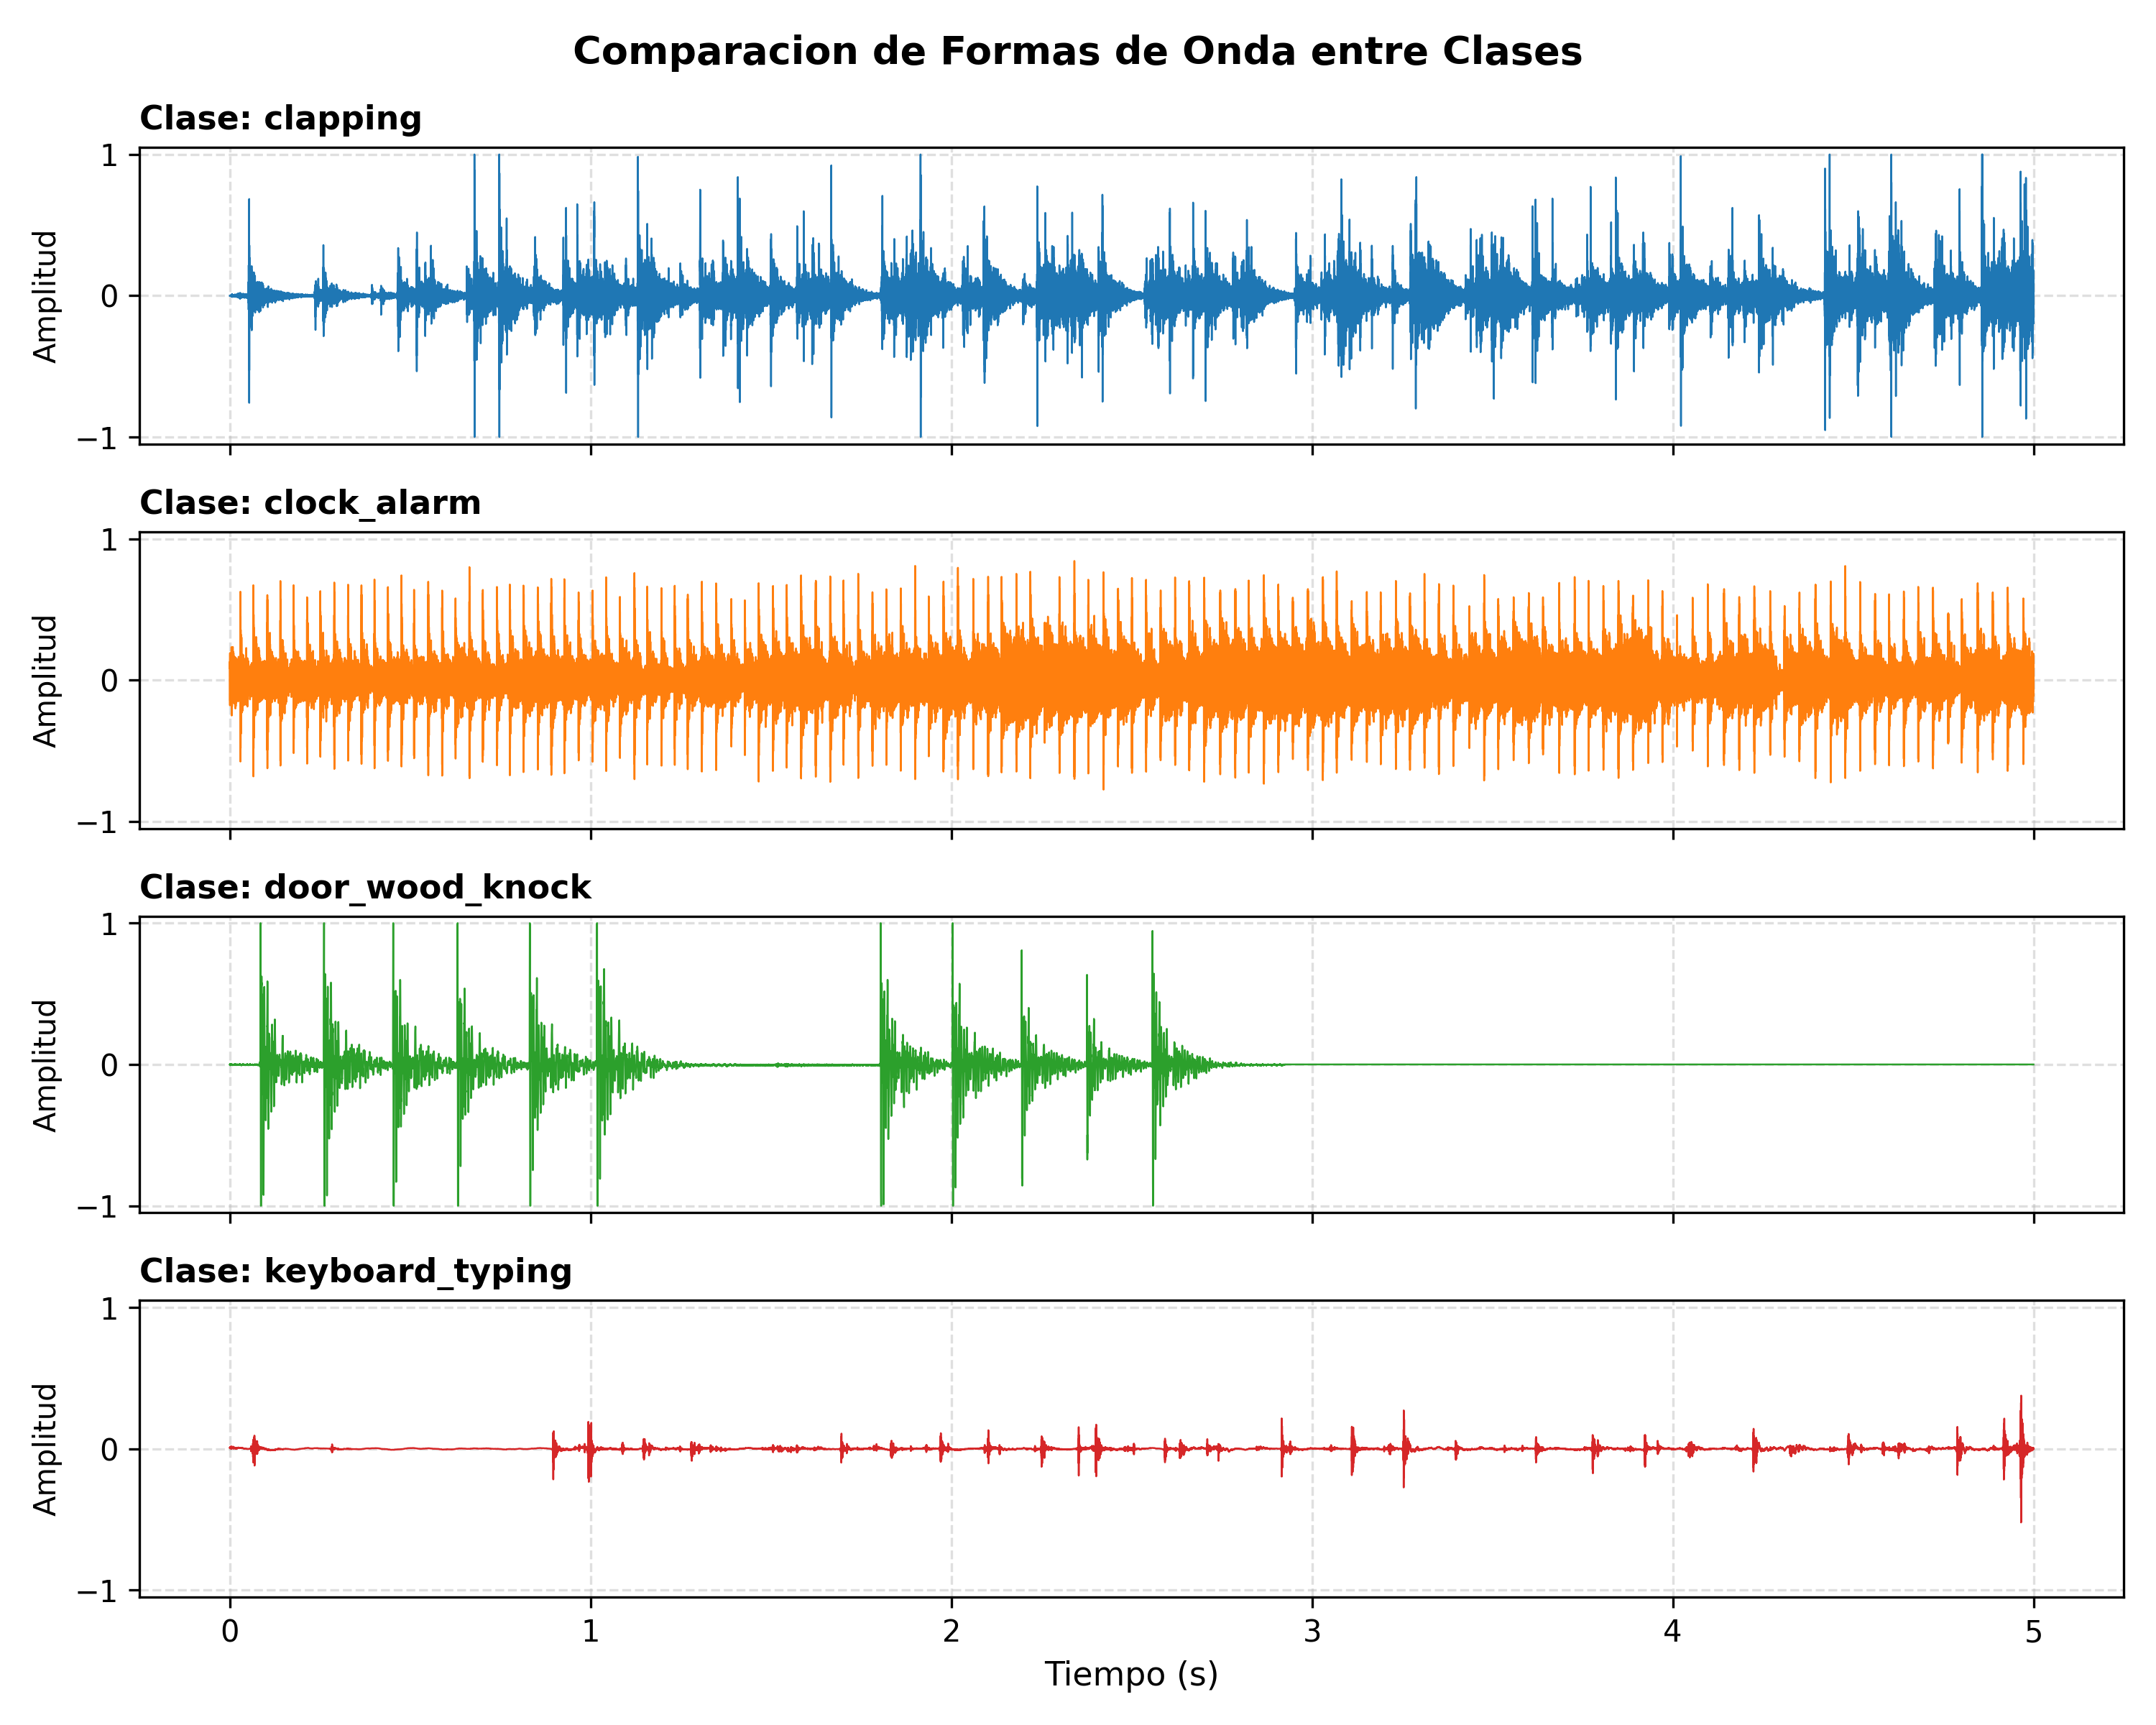

In [16]:
from IPython.display import Image, display
import explore_data
importlib.reload(explore_data)

explore_data.plot_class_distribution()
explore_data.plot_waveforms()

res_dir = 'results' if os.path.exists('results') else os.path.join('..', 'results')
display(Image(filename=os.path.join(res_dir, 'class_distribution.png')))
display(Image(filename=os.path.join(res_dir, 'waveform_sample.png')))
display(Image(filename=os.path.join(res_dir, 'waveform_comparison.png')))

## 3. Conversion de Audio a Espectrogramas (STFT)
Convertimos las senales a representaciones bidimensionales de tiempo vs frecuencia en escala logaritmica (dB).

Grafica guardada: c:\Users\Usuario\Desktop\lucianaIA2\results\spectrograms.png


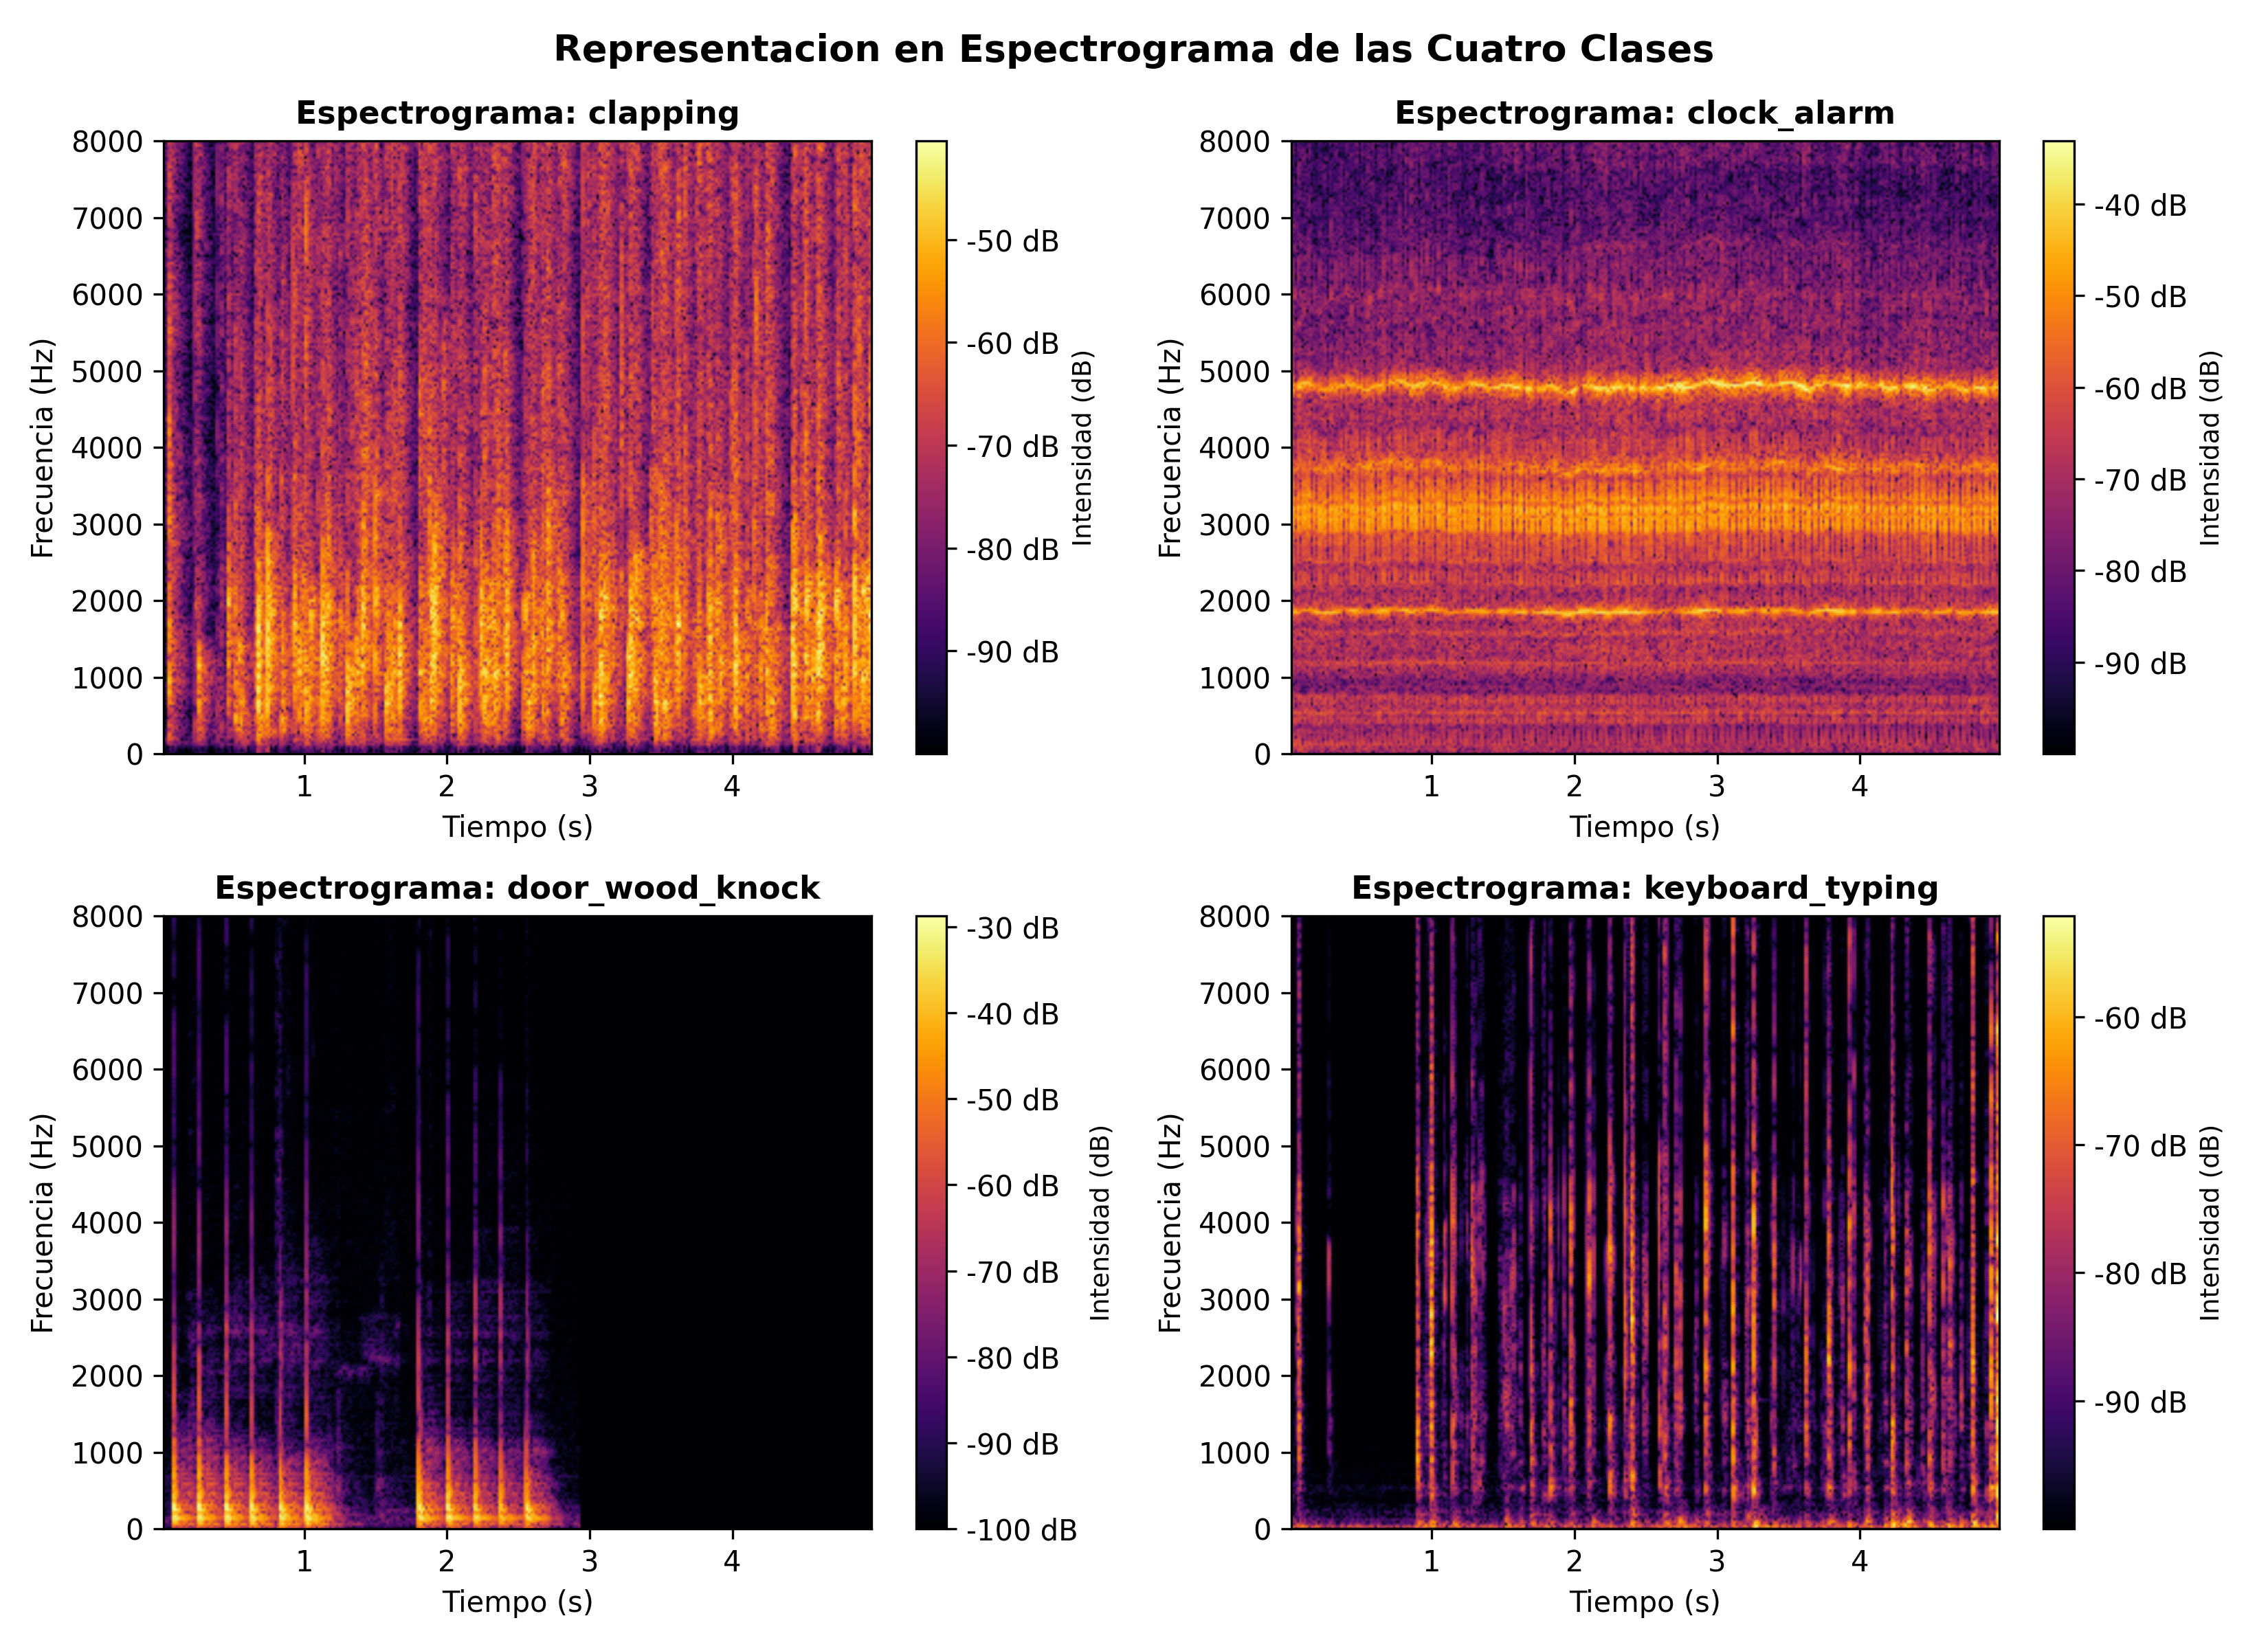

In [17]:
explore_data.plot_spectrograms()
res_dir = 'results' if os.path.exists('results') else os.path.join('..', 'results')
display(Image(filename=os.path.join(res_dir, 'spectrograms.png')))

## 4. Pipeline de Preprocesamiento y Division Estratificada
Re-muestreo a 16 kHz, extraccion de espectrograma 64x64, normalizacion Min-Max [0, 1] y division de datos en 70% entrenamiento (112), 15% validacion (24) y 15% prueba (24).

In [18]:
import preprocess
importlib.reload(preprocess)

(X_train, y_train), (X_val, y_val), (X_test, y_test) = preprocess.get_train_val_test_split()
print(f'Dimensiones X_train : {X_train.shape}, y_train: {y_train.shape}')
print(f'Dimensiones X_val   : {X_val.shape}, y_val: {y_val.shape}')
print(f'Dimensiones X_test  : {X_test.shape}, y_test: {y_test.shape}')

Dimensiones X_train : (112, 64, 64, 1), y_train: (112,)
Dimensiones X_val   : (24, 64, 64, 1), y_val: (24,)
Dimensiones X_test  : (24, 64, 64, 1), y_test: (24,)


## 5. Arquitectura de la TinyML CNN
Definicion de la arquitectura compacta adecuada para microcontroladores (2 capas Conv2D + MaxPooling + Dense).

In [19]:
import model
importlib.reload(model)
model.print_model_info()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │       262,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 267,108 (1.02 MB)

 Trainable params: 267,108 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

DETALLES DE LA ARQUITECTURA TINYML CNN
Total de parametros      : 267,108
Parametros entrenables   : 267,108
Tamano estimado en FP32  : 1043.39 KB
Tamano estimado en INT8  : 260.85 KB


## 6. Curvas de Aprendizaje (Accuracy y Loss)
Analisis de la convergencia y regularizacion durante el entrenamiento.

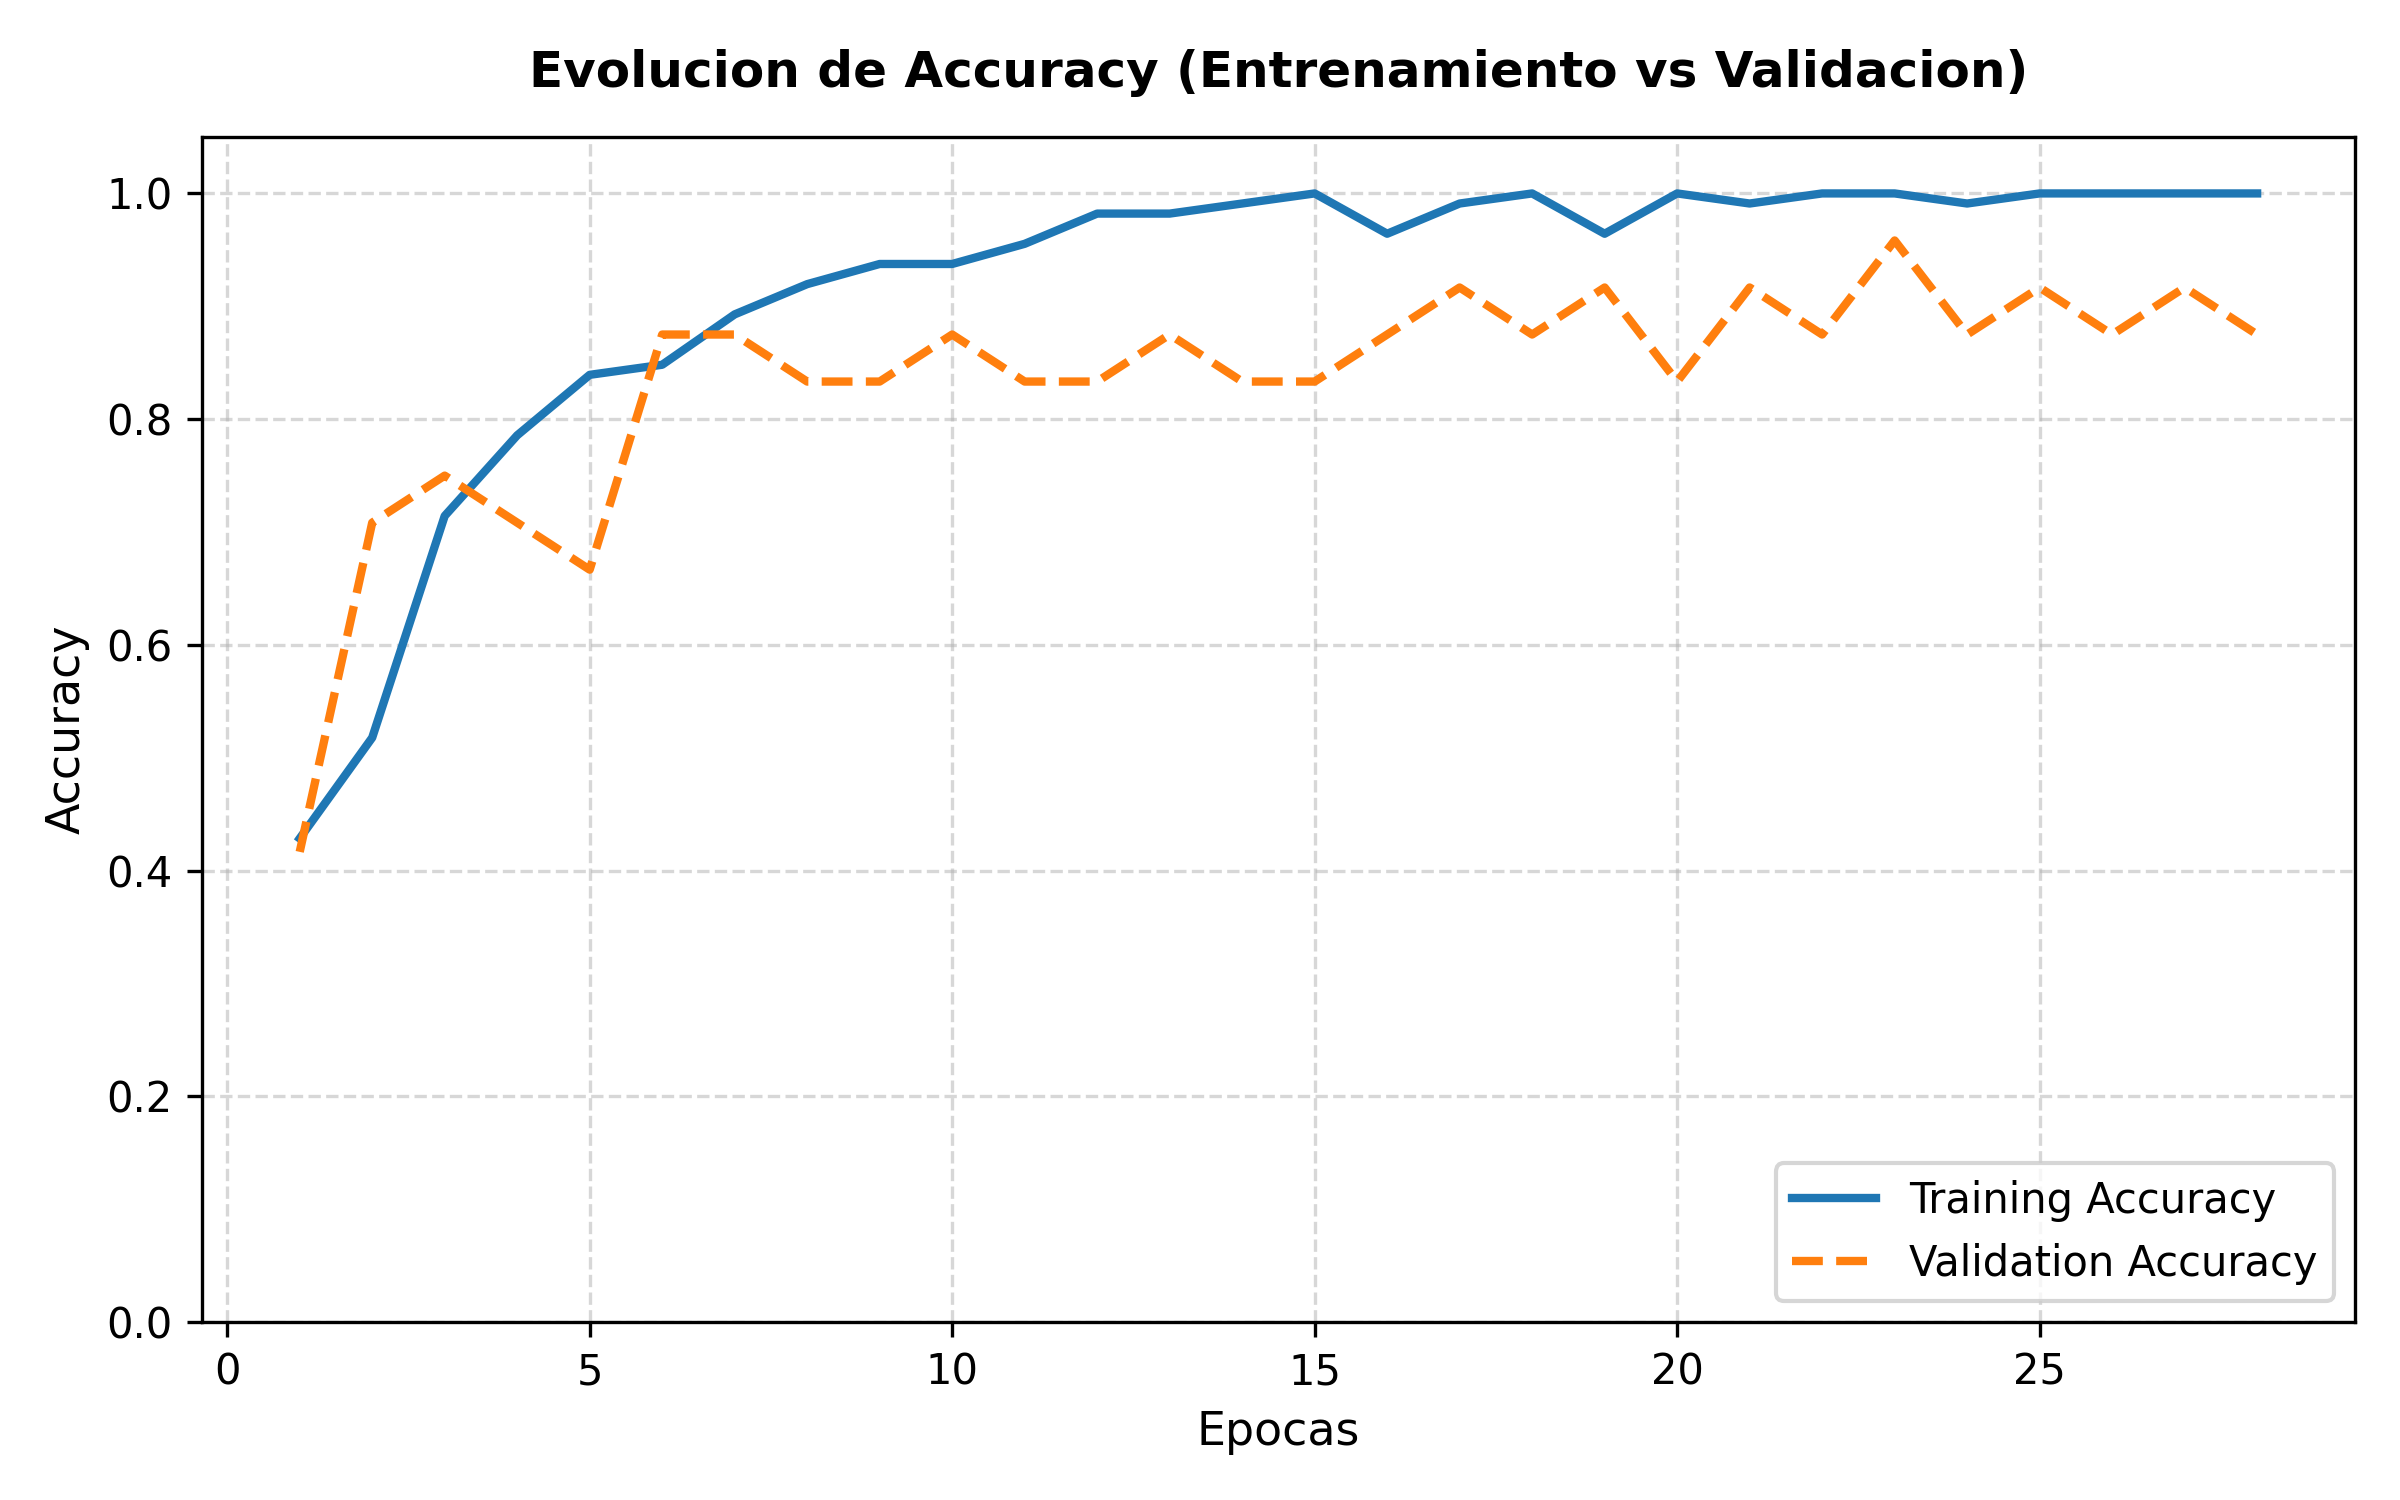

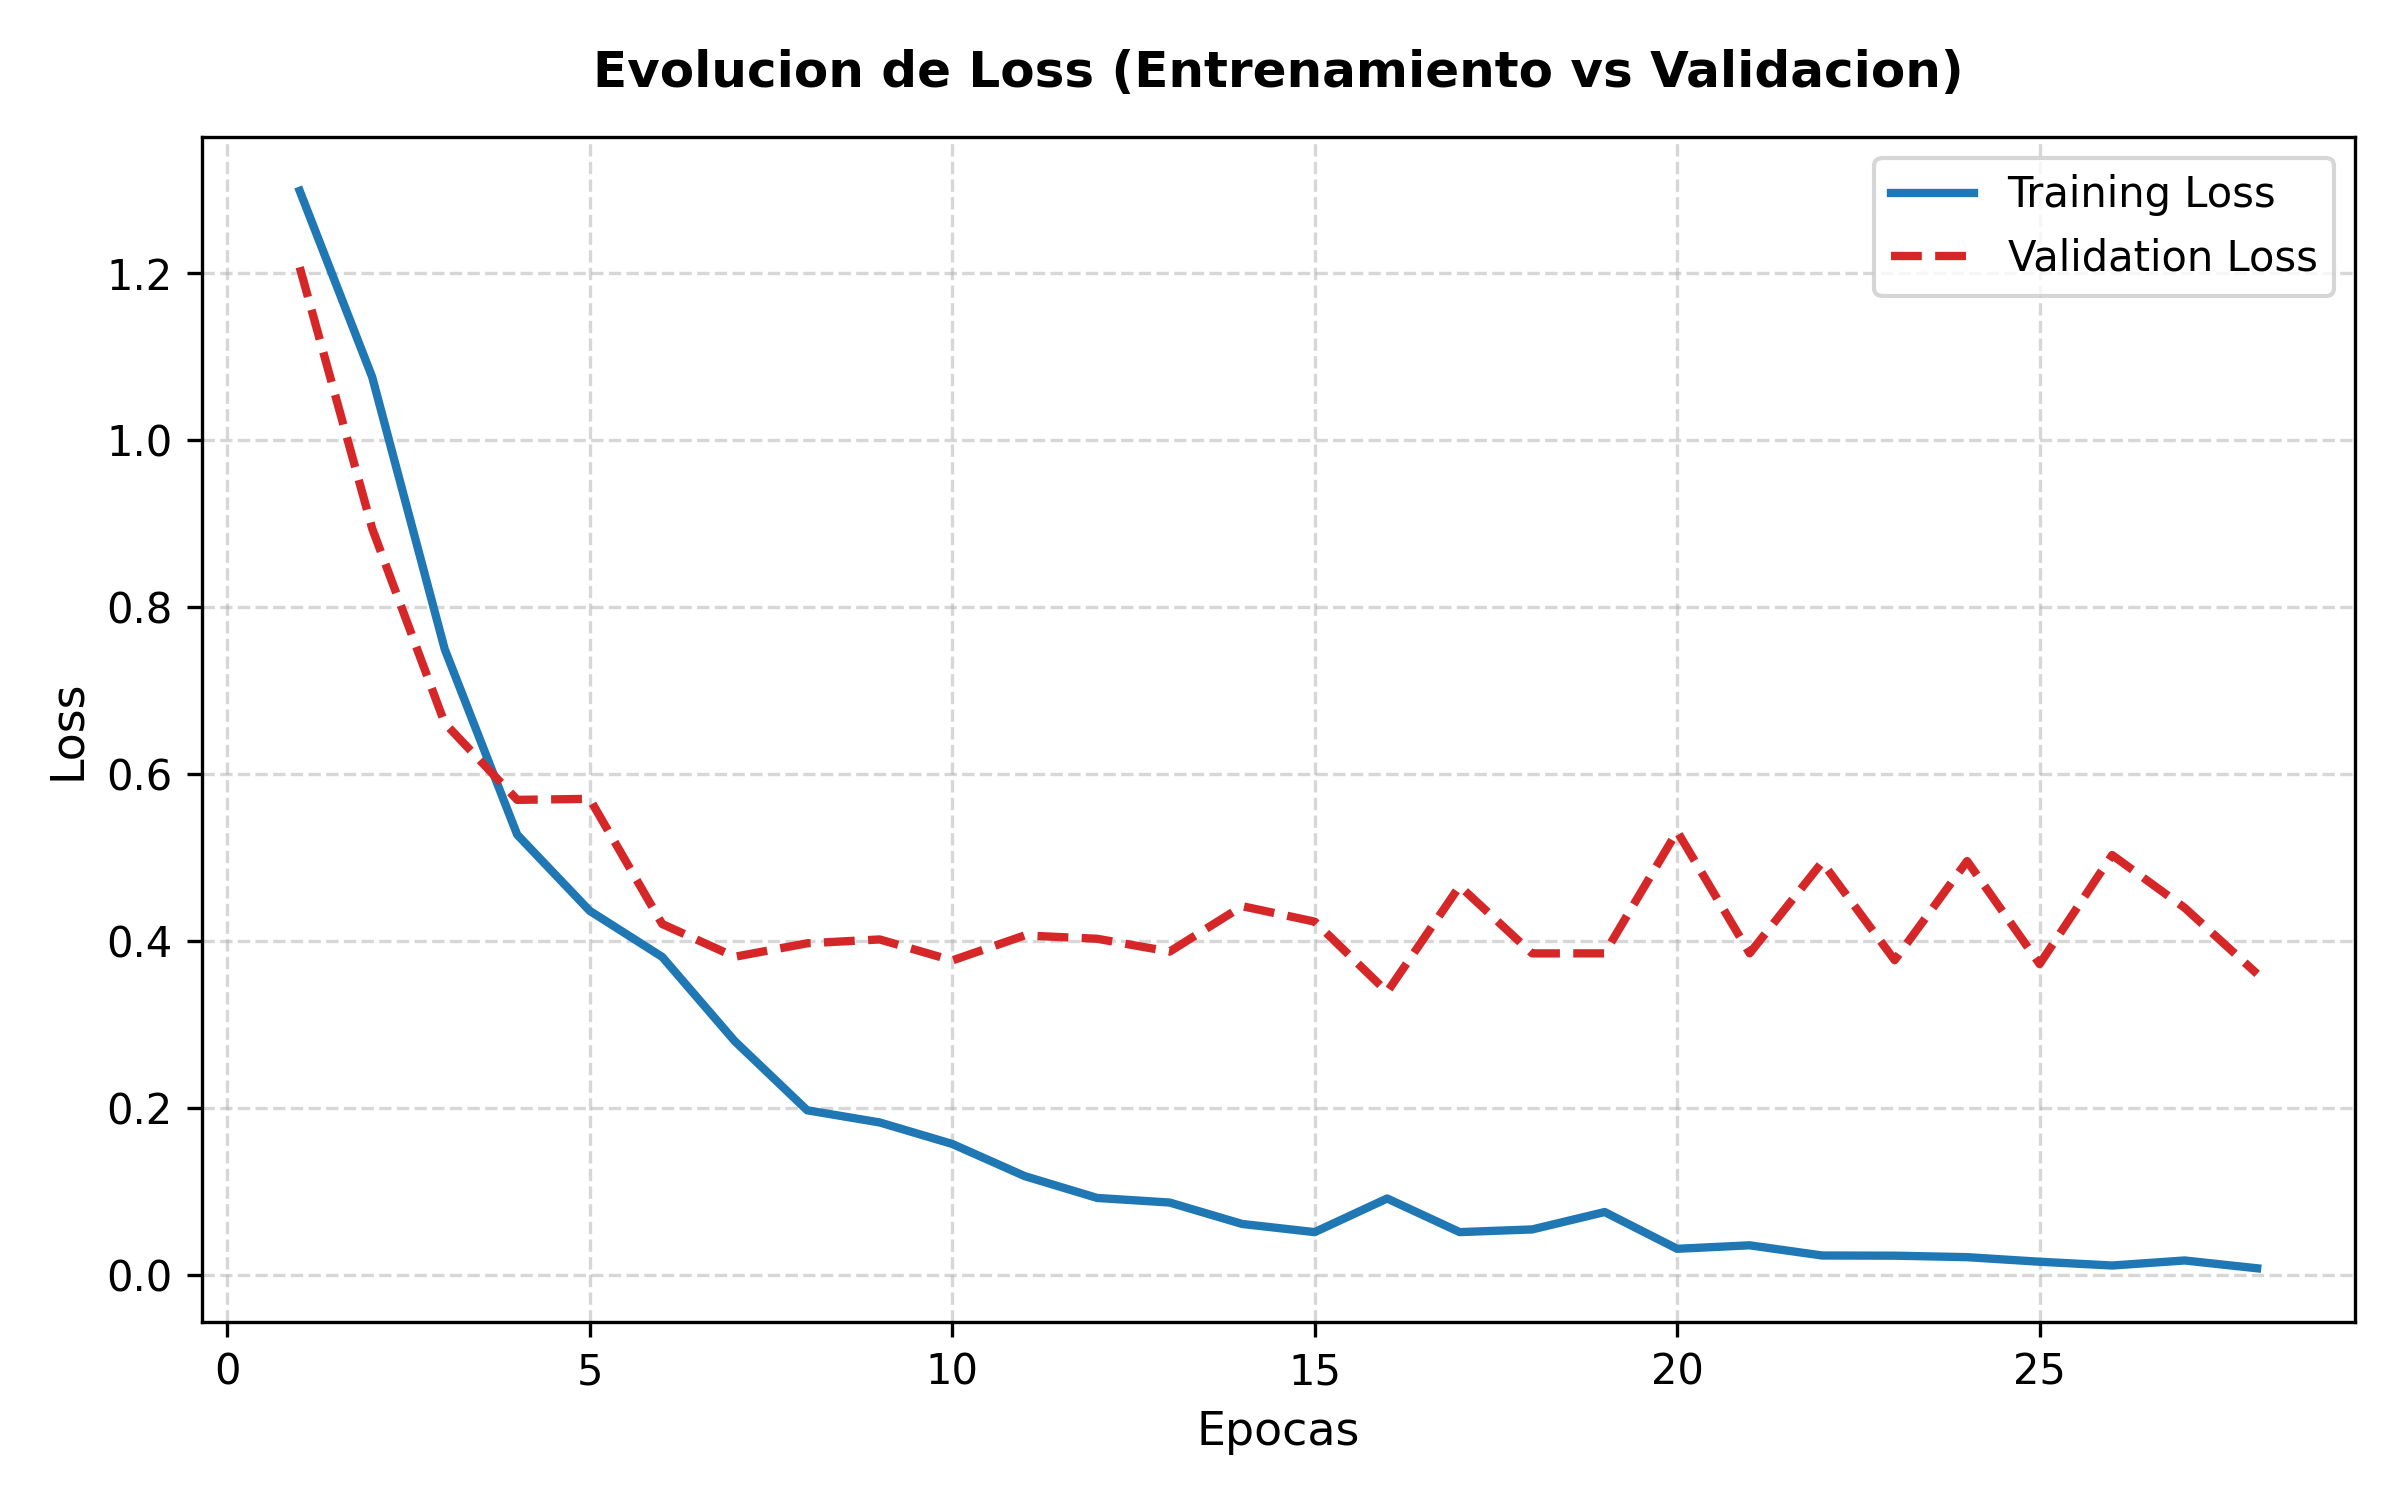

In [20]:
res_dir = 'results' if os.path.exists('results') else os.path.join('..', 'results')
display(Image(filename=os.path.join(res_dir, 'training_validation_accuracy.png')))
display(Image(filename=os.path.join(res_dir, 'training_validation_loss.png')))

## 7. Evaluacion en el Conjunto de Prueba y Matriz de Confusion
Evaluacion rigurosa de metricas ponderadas y deteccion de patrones acusticos confusos.

FASE 8 Y 9: EVALUACION DEL MODELO FP32

Accuracy  : 0.8750 (87.50%)
Precision : 0.9167
Recall    : 0.8750
F1-Score  : 0.8773

Reporte de Clasificacion:
------------------------------------------------------------
                 precision    recall  f1-score   support

       clapping     1.0000    0.6667    0.8000         6
    clock_alarm     1.0000    0.8333    0.9091         6
door_wood_knock     1.0000    1.0000    1.0000         6
keyboard_typing     0.6667    1.0000    0.8000         6

       accuracy                         0.8750        24
      macro avg     0.9167    0.8750    0.8773        24
   weighted avg     0.9167    0.8750    0.8773        24

Matriz de Confusion (valores absolutos):
[[4 0 0 2]
 [0 5 0 1]
 [0 0 6 0]
 [0 0 0 6]]

Grafica guardada: c:\Users\Usuario\Desktop\lucianaIA2\results\confusion_matrix.png


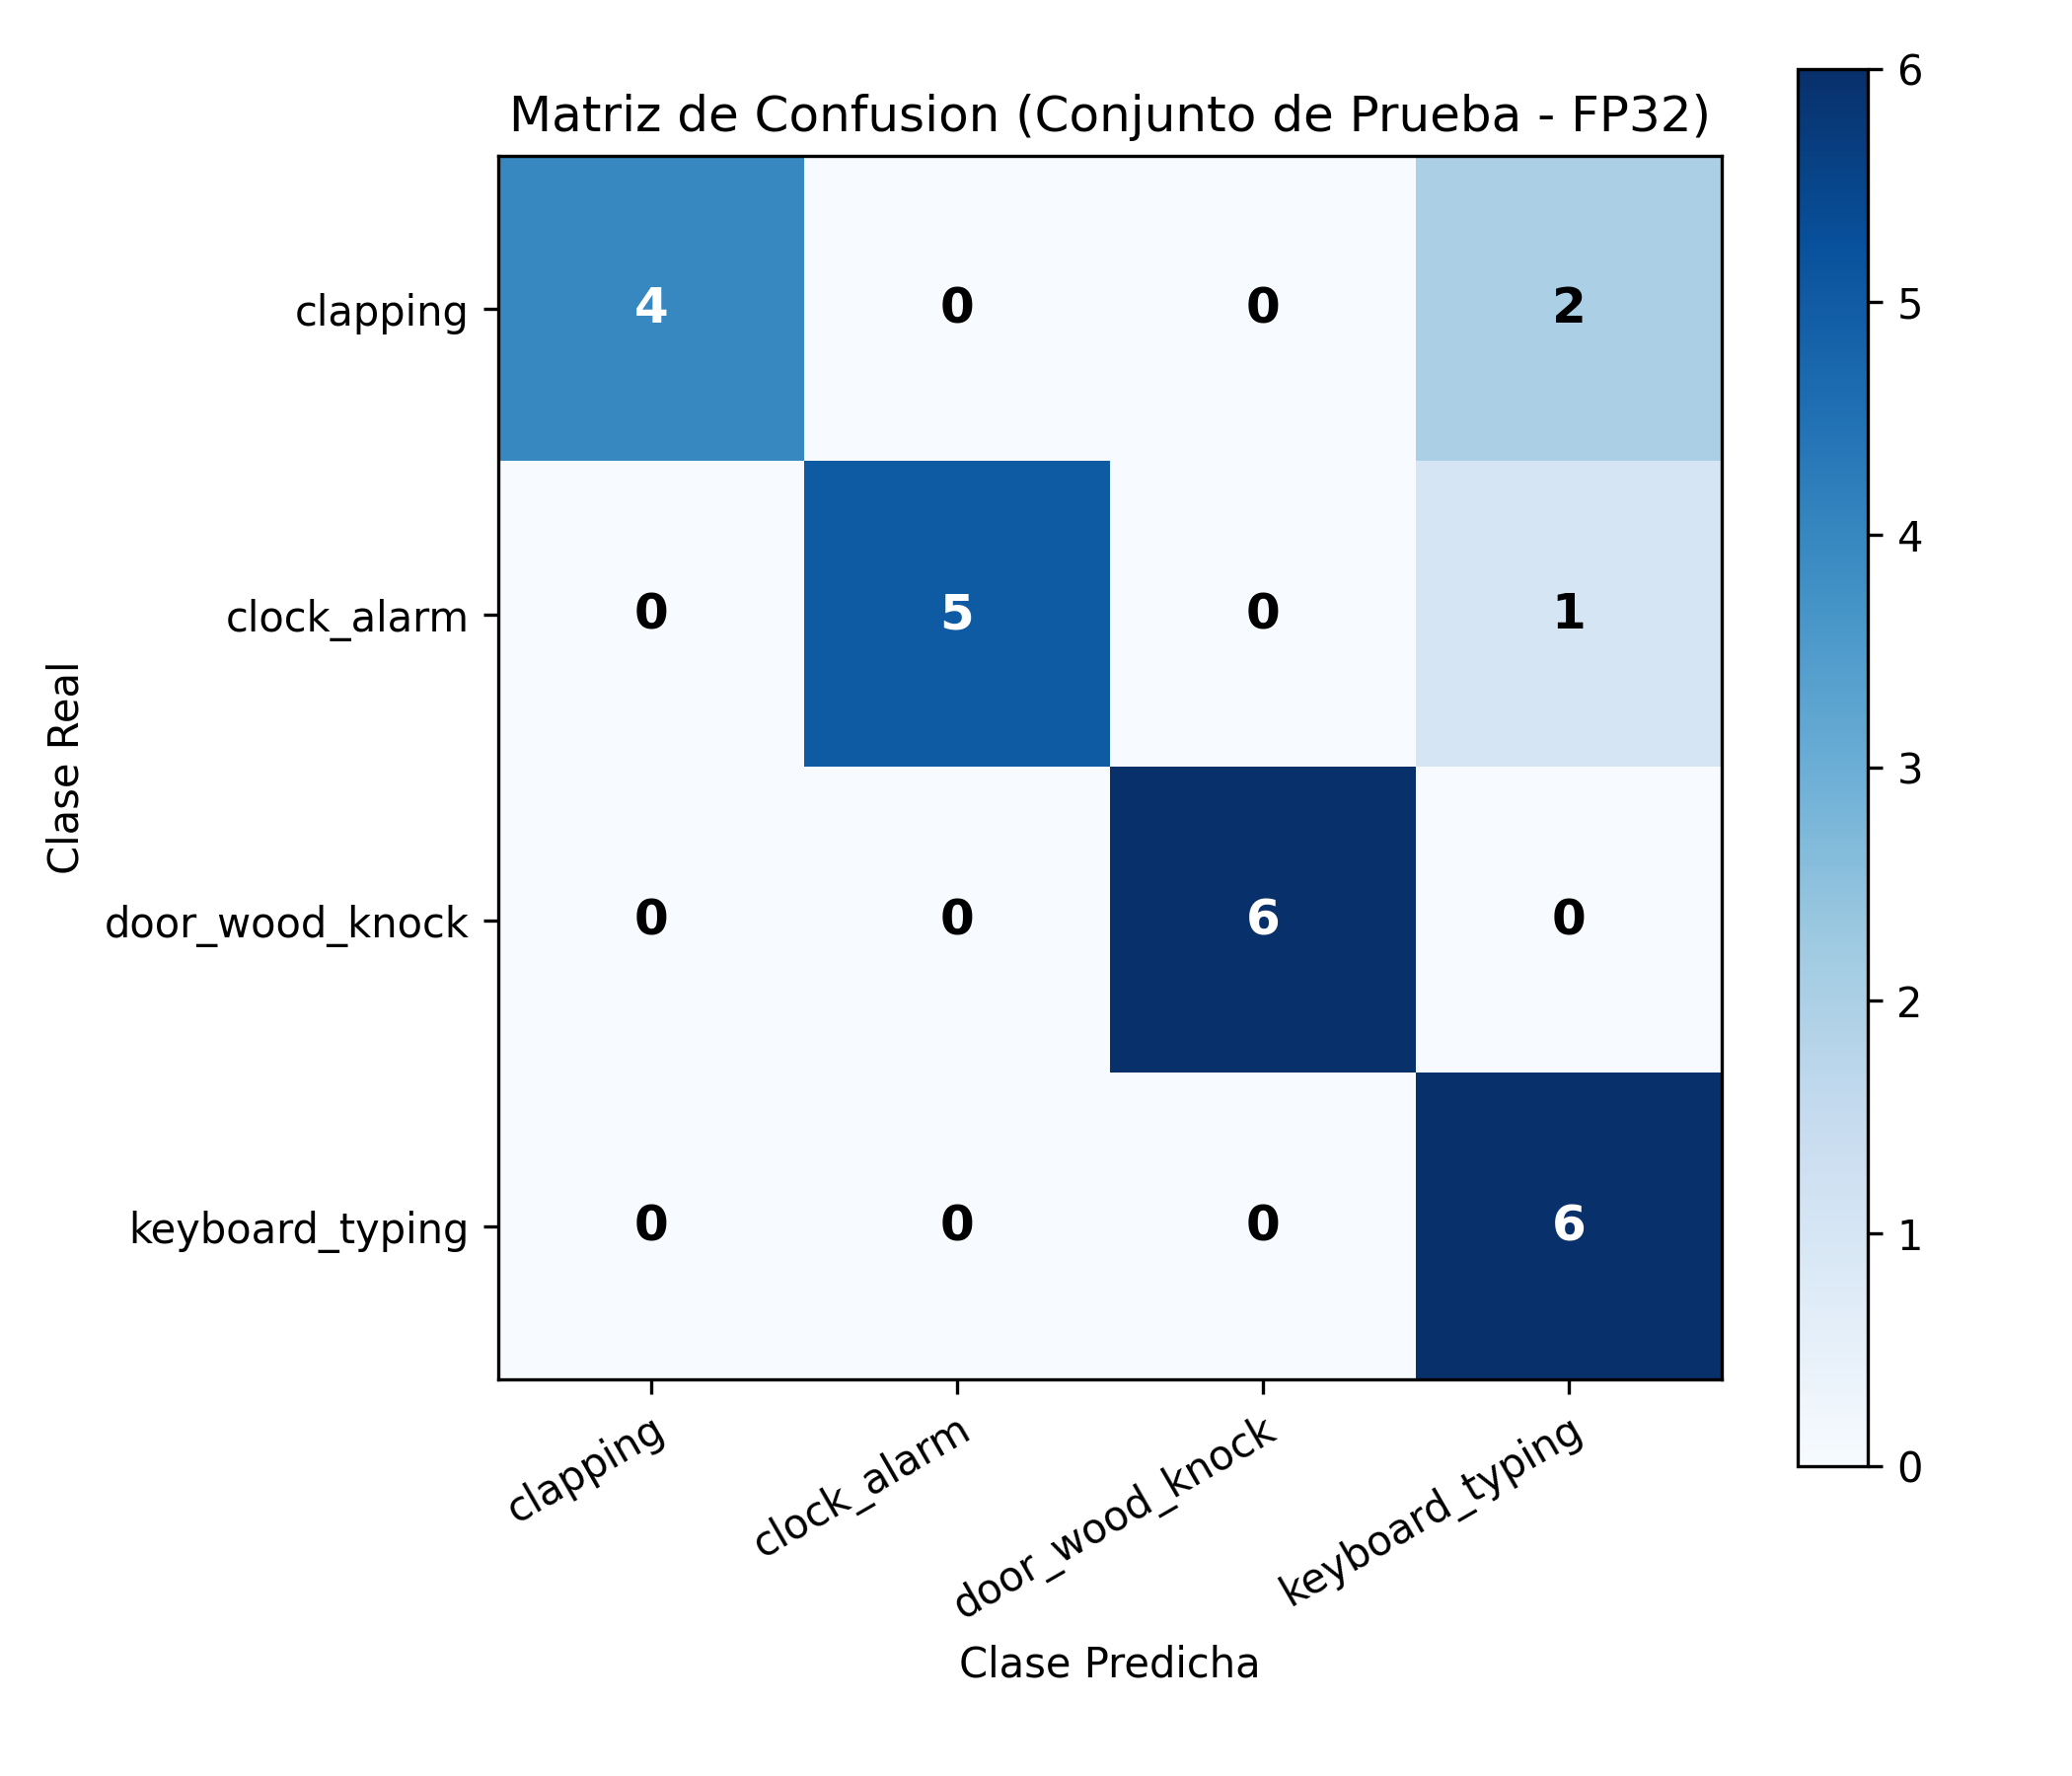

In [21]:
import evaluate
importlib.reload(evaluate)
metrics = evaluate.evaluate_model()
res_dir = 'results' if os.path.exists('results') else os.path.join('..', 'results')
display(Image(filename=os.path.join(res_dir, 'confusion_matrix.png')))

## 8. Conversion a TensorFlow Lite y Cuantizacion INT8
Optimizacion post-entrenamiento de FP32 (32 bits) a INT8 (8 bits enteros) con dataset representativo.

FASE 10, 11 Y 12: CONVERSION A TFLITE Y CUANTIZACION INT8

--- 1. Convirtiendo a TensorFlow Lite (FP32) ---
Saved artifact at 'C:\Users\Usuario\AppData\Local\Temp\tmpby6xjmp0'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 64, 64, 1), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  2722874760208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2722415836048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2722874768848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2722876850832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2722876852752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2722876866000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2722876862160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2722876853328: TensorSpec(shape=(), dtype=tf.resource, name=None)
Modelo FP32 guardado: c:\Users\Usuar

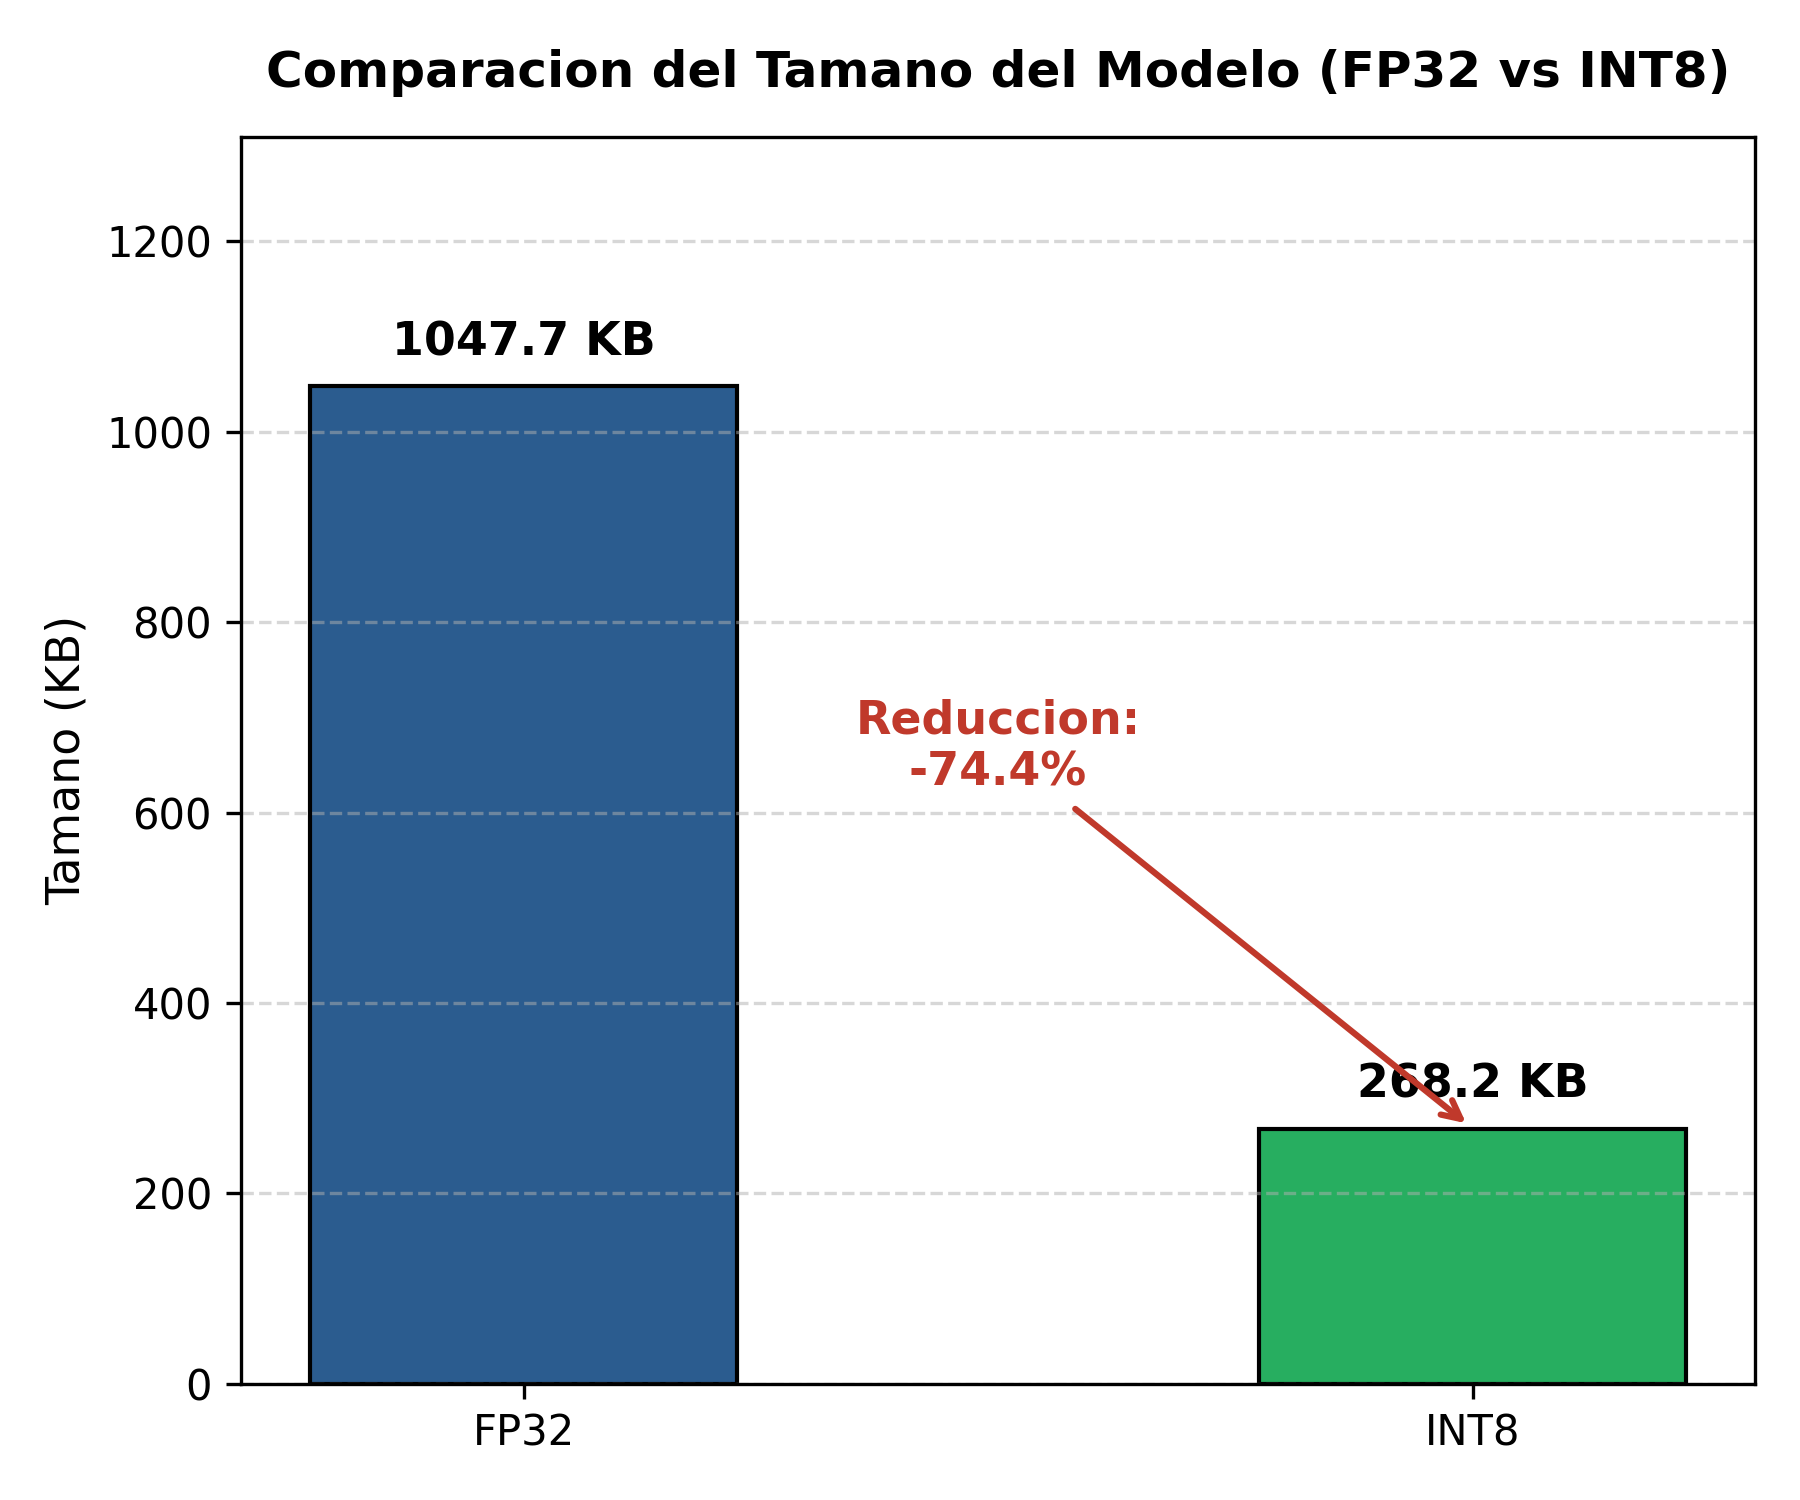

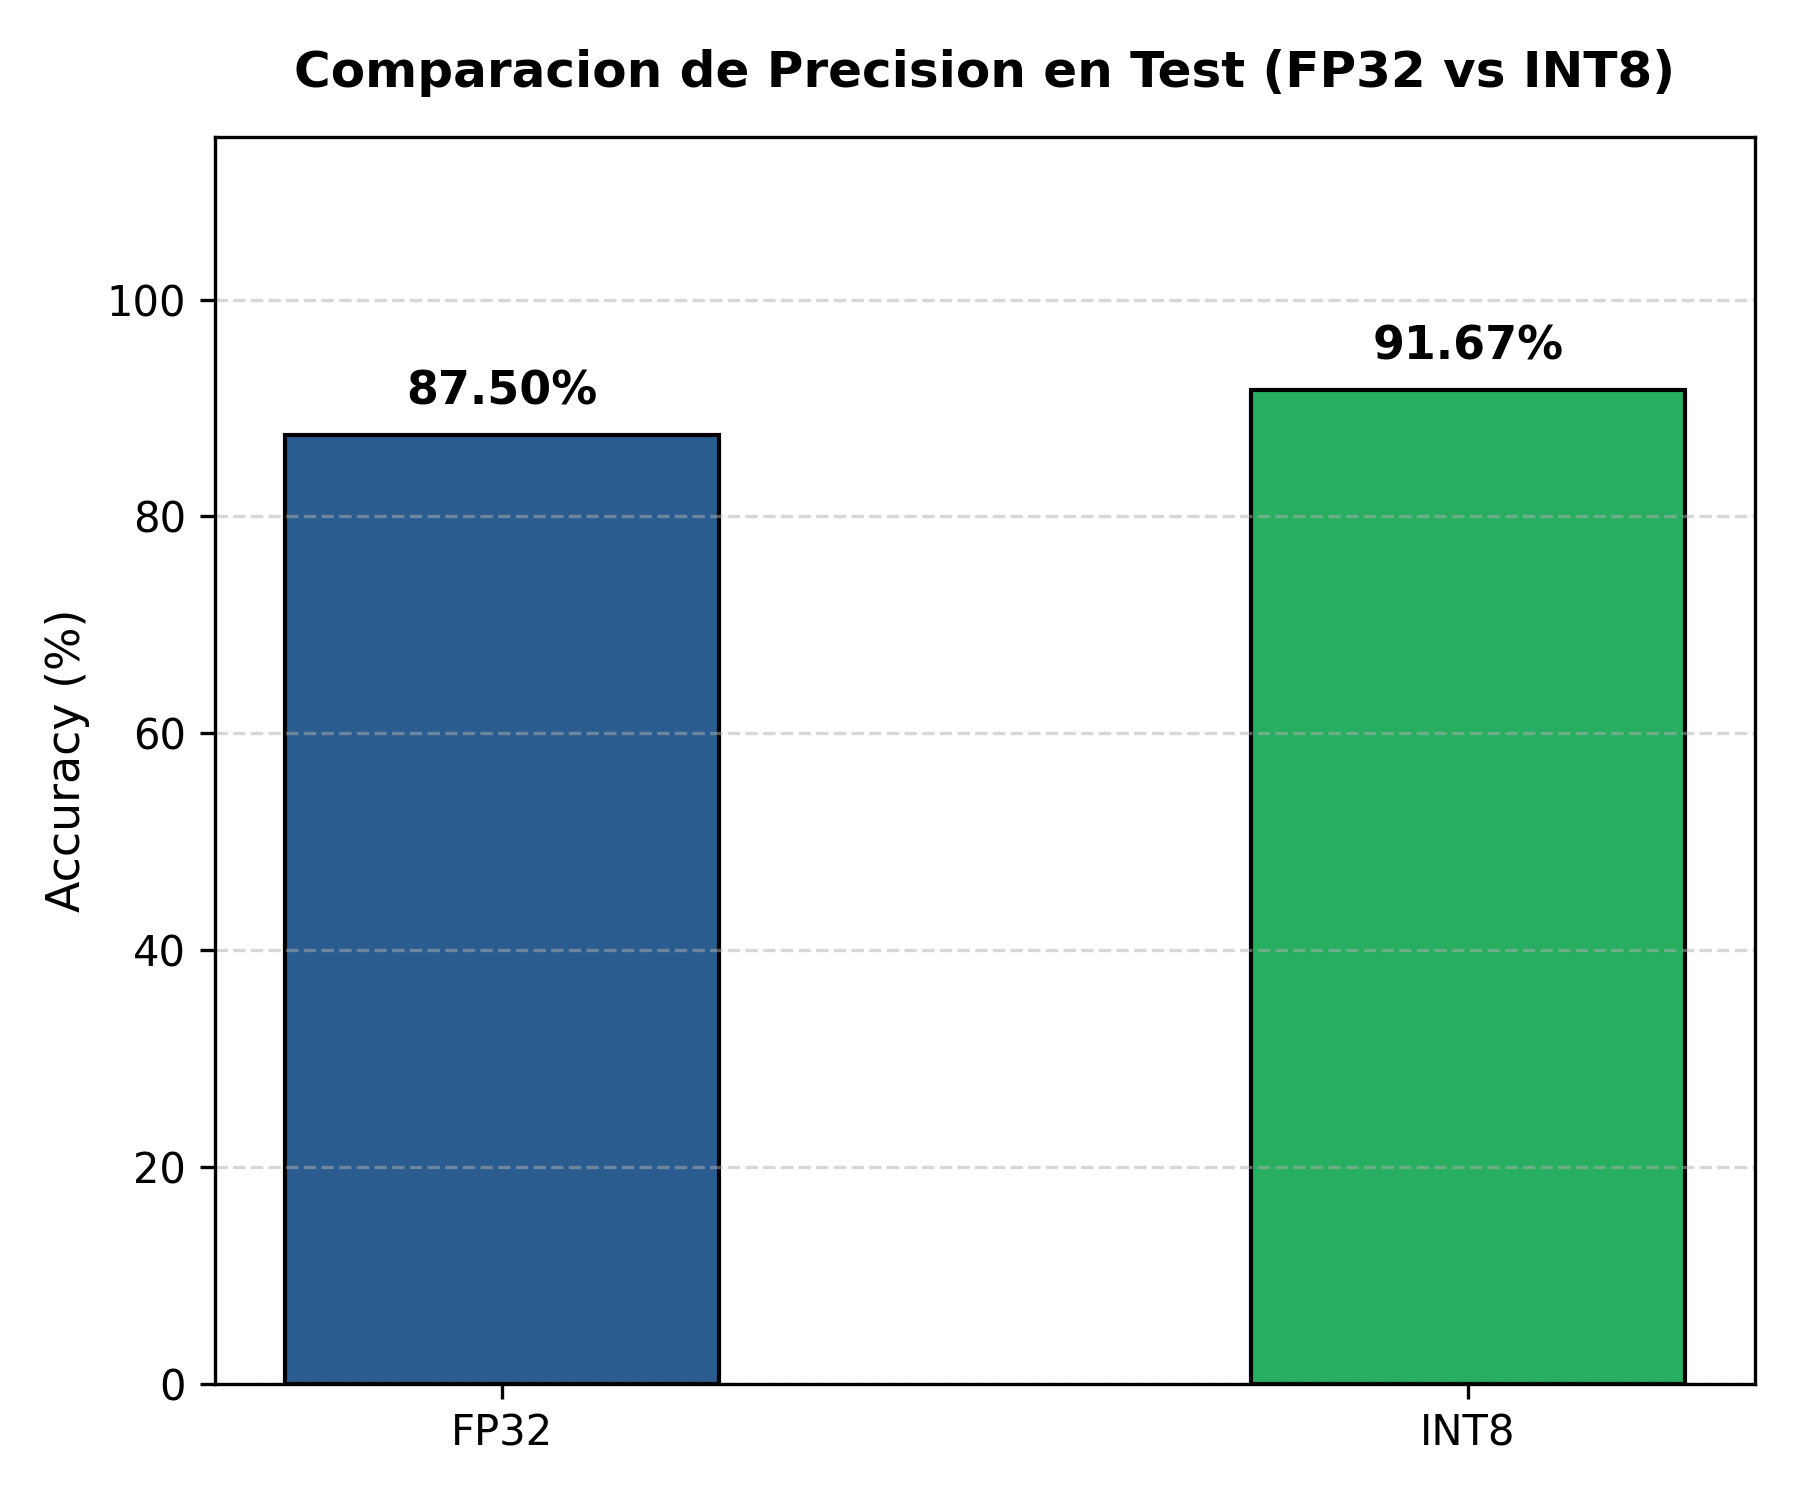

In [22]:
import quantization
importlib.reload(quantization)
summary = quantization.run_quantization_and_comparison()
res_dir = 'results' if os.path.exists('results') else os.path.join('..', 'results')
display(Image(filename=os.path.join(res_dir, 'model_size_comparison.png')))
display(Image(filename=os.path.join(res_dir, 'model_accuracy_comparison.png')))

## 9. Resultados Consolidados
Lectura del archivo consolidado CSV con las metricas reales.

In [23]:
import pandas as pd
res_dir = 'results' if os.path.exists('results') else os.path.join('..', 'results')
csv_path = os.path.join(res_dir, 'results_summary.csv')
df = pd.read_csv(csv_path)
display(df)

,model,format,accuracy,size_bytes,size_kb
0,TinyCNN_FP32,FP32,0.8750,1072812,1047.67
1,TinyCNN_INT8,INT8,0.9167,274608,268.17
